# 03 — Modelo e resíduos

**Pergunta deste notebook:** que preço/m² é normal para um imóvel com estas
características, e quais são os anúncios que se afastam disso?

O objectivo do projeto não é acertar no preço. É **encontrar os anúncios que
saem do padrão** — e para isso o que interessa é o resíduo, não o R².

Trabalha sobre `data/processed/anuncios_coimbra.csv`, produzido pelo `02`.

## Como este notebook funciona

Três regras que vêm dos notebooks anteriores:

1. **Lista explícita de features.** Nunca `drop(columns=...)`. Com uma lista,
   nada entra sem ser escrito; com `drop`, tudo entra quando alguém se esquece.
2. **Tudo o que aprende dos dados vai dentro do `Pipeline`**, ajustado só no
   treino. Imputação, encoding e escalonamento incluídos.
3. **Divisão por grupo, não aleatória.** Há empreendimentos com 17 frações
   idênticas; ao acaso, umas ficam no treino e outras no teste, e o modelo
   parece melhor do que é.

## Setup

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 65)
pd.set_option("display.width", 200)

from src.config import PROCESSED, OUTPUTS

ficheiro = PROCESSED / "anuncios_coimbra.csv"
if not ficheiro.exists():
    raise SystemExit("Falta o dataset limpo. Corre o 02_limpeza até ao fim.")

df = pd.read_csv(ficheiro)
print(f"{len(df)} anúncios, {df.shape[1]} colunas")

1382 anúncios, 63 colunas


---
## 0. Ponto de partida

O alvo e o que dele se sabe. Os anúncios sem preço ficam de parte — não têm
alvo para treinar, mas são exactamente aqueles a que se quer atribuir um valor
no fim.

com alvo (treino/teste) ... 1369
sem alvo (preço oculto) ... 13

count    1369.0
mean     4019.0
std      1314.0
min       208.0
25%      3176.0
50%      4044.0
75%      4847.0
max      8524.0


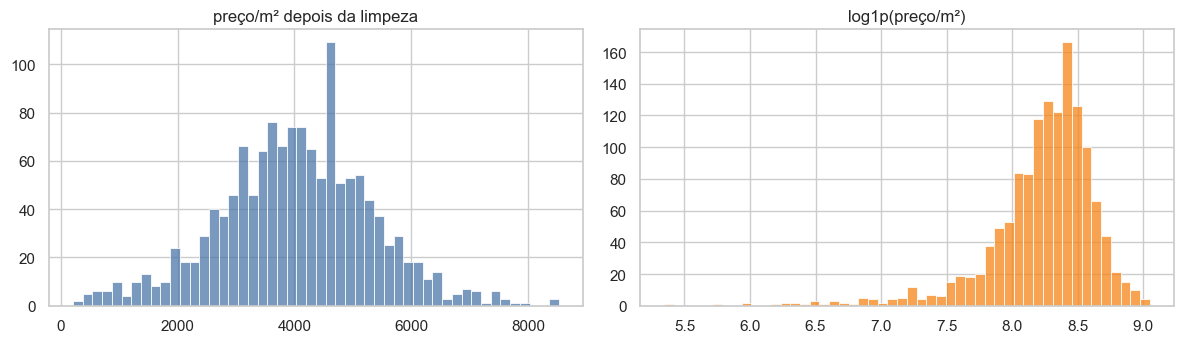

In [2]:
ALVO = "preco_m2"

com_alvo = df[df[ALVO].notna()].copy()
sem_alvo = df[df[ALVO].isna()].copy()

print(f"com alvo (treino/teste) ... {len(com_alvo)}")
print(f"sem alvo (preço oculto) ... {len(sem_alvo)}")
print()
print(com_alvo[ALVO].describe().round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(com_alvo[ALVO], bins=50, color="#4C78A8", ax=axes[0])
axes[0].set_title("preço/m² depois da limpeza")
sns.histplot(np.log1p(com_alvo[ALVO]), bins=50, color="#F58518", ax=axes[1])
axes[1].set_title("log1p(preço/m²)")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

A distribuição ficou simétrica. A assimetria passa de 3,7 (antes da
limpeza) para −0,04, e a curtose de 63,2 para 0,33. Média e mediana quase
coincidem (4 019 e 4 044). O alvo não precisa de transformação — o painel
do log1p confirma-o, criando uma cauda esquerda que não existia.

Há um pico visível junto aos 4 600 €/m². Não é acaso: são três
empreendimentos de obra nova com preço/m² quase idêntico entre frações — 12
T3 de um condomínio da Century 21, 8 T3 e 7 T4 na Quinta da Portela.

É a razão de a divisão treino/teste ser por grupo_empreendimento e não
aleatória. Com 12 frações iguais, uma divisão ao acaso deixaria o modelo ver
no treino praticamente a resposta do teste.

Nota para os resíduos: dentro de cada um destes grupos os desvios vão ser
quase nulos, porque as unidades são idênticas. Não é mérito do modelo.

---
## 1. Features

A lista é explícita e cada exclusão tem motivo escrito. É a única defesa
contra o leakage: uma coluna nova no dataset nunca entra sozinha.

In [3]:
FEATURES_NUM = [
    "area_m2", "tipologia_ord", "idade_edificio", "certificado_ord",
    "estado_ord", "n_casas_banho", "piso", "n_pisos_edificio",
    "dist_universidade_km", "dist_solum_km", "dist_huc_km",
    "n_fotos", "dias_em_mercado", "n_campos_preenchidos",
]

FEATURES_CAT = ["bairro_grupo", "tipo_imovel", "agencia_grupo", "mercado"]

FEATURES_BIN = [c for c in df.columns if c.startswith("tem_")] + [
    "obra_nova", "precisa_obras", "certificado_isento",
]

FEATURES = FEATURES_NUM + FEATURES_CAT + FEATURES_BIN
FEATURES = [c for c in FEATURES if c in df.columns]

print(f"{len(FEATURES)} features: "
      f"{len(FEATURES_NUM)} numéricas, {len(FEATURES_CAT)} categóricas, "
      f"{len(FEATURES_BIN)} binárias")
print()
print("nulos por feature (só as que têm):")
n = com_alvo[FEATURES].isna().sum()
print(n[n > 0].sort_values(ascending=False).to_string())

35 features: 14 numéricas, 4 categóricas, 17 binárias

nulos por feature (só as que têm):
n_pisos_edificio        1075
idade_edificio           800
piso                     724
n_casas_banho            358
estado_ord               341
certificado_ord          192
dist_solum_km             17
dist_universidade_km      17
mercado                   17
dist_huc_km               17
tipologia_ord              4
bairro_grupo               3


In [4]:
com_alvo.head(10)

,ad_id,titulo,preco_eur,preco_oculto,area_m2,preco_m2,tipologia,piso,tipo_imovel,data_publicacao,data_republicacao,agencia,particular,promovido,origem,n_fotos,freguesia,bairro,lat,lon,raio_precisao_m,data_modificacao,n_casas_banho,descricao,ano_construcao,certificado_energetico,estado_conservacao,tipo_edificio,n_pisos_edificio,aquecimento,tipo_janelas,mercado,dist_universidade_km,dist_solum_km,dist_huc_km,dist_polo_mais_proximo_km,agencia_grupo,dias_em_mercado,obra_nova,idade_edificio,tipologia_ord,certificado_ord,certificado_isento,estado_ord,precisa_obras,tem_ar_condicionado,tem_varanda,tem_jardim,tem_piscina,tem_cozinha_separada,tem_terraco,tem_garagem,tem_arrecadacao,tem_res_do_chao,tem_edificio_seguro,tem_ultimo_piso,tem_elevador,tem_acessibilidade,tem_seguranca,bairro_grupo,n_campos_preenchidos,grupo_empreendimento,comprimento_descricao
0,19251427,Apartamento T3 - Olivais - Coimbra/Venda,279000.0,False,92.0,3032.61,T3,2.0,FLAT,2026-08-20T19:21:54Z,2026-08-20 19:22:07,Casas Prime - Surpresa Tranquila LDA,False,False,urn:partner:ximo,32,Santo António dos Olivais,Quinta da Maia,40.212704,-8.396301,100.0,2026-08-21T17:06:00Z,2.0,"Apartamento T3 nos Olivais, Coimbra – Próximo HUC e Solum \n\...",1983.0,e,ready_to_use,block,NaN,NaN,aluminium,secondary,2.631,1.129,1.686,1.129,Casas Prime - Surpresa Tranquila LDA,12.0,False,43.0,3.0,2.0,False,2.0,False,False,True,False,False,False,False,False,False,False,True,False,False,False,True,Quinta da Maia,5,267,2648
1,19235209,Duplex à venda na Rua Pêro Vaz de Caminha,435000.0,False,106.0,4103.77,T4,4.0,FLAT,2026-08-05T18:42:23Z,2026-08-20 18:53:59,Sofia Apolonia,False,False,urn:site:local,11,Santo António dos Olivais,Bairro Norton de Matos,40.197390,-8.404993,0.0,2026-08-20T17:53:59Z,2.0,Duplex T4+1 Renovado em Coimbra - Pronto a HabitarDescobre es...,1987.0,e,ready_to_use,apartment,NaN,electrical,plastic,secondary,2.139,0.739,2.701,0.739,Outra independente,27.0,False,39.0,4.0,2.0,False,2.0,False,True,True,False,False,False,False,True,False,False,True,False,True,False,True,Bairro Norton de Matos,6,709,1828
2,19049650,Apartamento T9 em Dúplex com garagem e duas entradas independ...,379000.0,False,100.0,3790.00,T5,NaN,FLAT,2026-02-20T17:00:59Z,2026-08-20 13:03:13,KW Union - Coimbra,False,False,urn:partner:soukwportugal,35,Santo António dos Olivais,Alto de S. João - Portela - Pinhal de Marrocos,40.190480,-8.418840,0.0,2026-08-22T12:02:49Z,3.0,"Apresentamos este exclusivo Apartamento T9 em Duplex, situado...",NaN,d,NaN,NaN,NaN,NaN,NaN,secondary,1.991,2.018,3.419,1.991,Keller Williams,193.0,False,NaN,5.0,3.0,False,NaN,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,Alto de S. João - Portela - Pinhal de Marrocos,1,556,2298
3,19108915,T1 de Luxo com Varanda | Garagem | Olivais Terrace | Classe A+,310000.0,False,70.0,4428.57,T1,NaN,FLAT,2026-04-10T16:00:43Z,2026-08-20 13:03:12,KW Union - Coimbra,False,False,urn:partner:soukwportugal,17,Santo António dos Olivais,Olivais,40.218060,-8.399690,0.0,2026-08-22T12:02:44Z,1.0,Descubra o privilégio de estrear um apartamento onde a susten...,NaN,aplus,to_completion,NaN,NaN,NaN,NaN,primary,2.567,1.606,1.173,1.173,Keller Williams,144.0,False,NaN,1.0,8.0,False,1.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Olivais,1,352,2151
4,19072604,R/C Fração Autónoma Conchada | [7] Unidades Rendimento | Yiel...,271000.0,False,191.0,1418.85,T6,NaN,FLAT,2026-03-10T19:01:14Z,2026-08-20 13:03:11,KW Union - Coimbra,False,False,urn:partner:soukwportugal,17,Santo António dos Olivais,Celas,40.214940,-8.428240,0.0,2026-08-22T12:02:30Z,2.0,"Apresentamos uma oportunidade rara no mercado de Coimbra, sit...",1946.0,d,to_renovation,NaN,NaN,NaN,NaN,secondary,0.851,2.498,1.454,0.851,Keller Williams,175.0,False,80.0,6.0,3.0,False,0.0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Celas,2,248,2175
5,18996638,Apartamento T3 NOVO áreas generosas & qualidade cons

### 1.1 · O que fica de fora, e porquê

| coluna | motivo |
|---|---|
| `preco_eur` | `preco_m2 = preco_eur / area_m2`. Com esta e a área, o modelo faz a divisão e dá R² 0,96 sem aprender nada. |
| `grupo_empreendimento` | construído a partir do preço; serve para dividir treino/teste, nunca como feature |
| `dist_polo_mais_proximo_km` | é o mínimo das outras três — informação repetida |
| `lat`, `lon` | coordenadas; já representadas nas distâncias. Ficam no ficheiro para o mapa do dashboard |
| `raio_precisao_m` | descreve a qualidade da medição, não o imóvel. Guardado para o teste de robustez da secção 5 |
| `titulo`, `descricao` | texto (features ja extraidas no 02) |
| `bairro`, `agencia`, `tipologia`, `certificado_energetico`, `estado_conservacao` | versões não agrupadas ou não ordinais das que entram |
| `preco_oculto`, `particular`, `promovido` | quase constantes (4 a 12 casos) |
| `origem`, `data_*` | metadados da recolha |

---
## 2. Divisão treino/teste

Por **grupo de empreendimento**, não ao acaso.

O `02` encontrou 148 grupos de anúncios com preço, área, tipologia e bairro
iguais ("grupo_empreendimento") — frações do mesmo condomínio, até 17 de uma vez. Numa divisão
aleatória, 12 ficam no treino e 5 no teste, e o modelo já viu praticamente a
resposta. O resultado sairia optimista sem que nada desse erro.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

grupos = com_alvo["grupo_empreendimento"]
divisor = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
i_treino, i_teste = next(divisor.split(com_alvo, groups=grupos))

treino = com_alvo.iloc[i_treino].copy()
teste = com_alvo.iloc[i_teste].copy()

X_treino, y_treino = treino[FEATURES], treino[ALVO]
X_teste, y_teste = teste[FEATURES], teste[ALVO]

print(f"treino: {len(treino):5d} anúncios, {treino.grupo_empreendimento.nunique():4d} grupos")
print(f"teste:  {len(teste):5d} anúncios, {teste.grupo_empreendimento.nunique():4d} grupos")
print(f"grupos partilhados entre os dois: "
      f"{len(set(treino.grupo_empreendimento) & set(teste.grupo_empreendimento))}")
print()
print(f"preço/m² mediano — treino {y_treino.median():.0f} | teste {y_teste.median():.0f}")

treino:  1031 anúncios,  840 grupos
teste:    338 anúncios,  281 grupos
grupos partilhados entre os dois: 0

preço/m² mediano — treino 4045 | teste 4032


*O número de grupos partilhados tem de ser **zero**. Confirma. E compara as
medianas: se forem muito diferentes, a divisão calhou desequilibrada e vale a
pena mudar a semente.*

---
## 3. Baselines

Antes de qualquer modelo, os números que ele tem de bater. Um modelo que não
supera a mediana não vale o que custa em complexidade.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score


def avaliar(modelo, nome, X_tr=None, y_tr=None, X_te=None, y_te=None):
    X_tr = X_treino if X_tr is None else X_tr
    y_tr = y_treino if y_tr is None else y_tr
    X_te = X_teste if X_te is None else X_te
    y_te = y_teste if y_te is None else y_te
    modelo.fit(X_tr, y_tr)
    p = modelo.predict(X_te)
    erro_pct = np.abs(p - y_te) / y_te
    return {"modelo": nome,
            "MAE_eur_m2": round(mean_absolute_error(y_te, p)),
            "erro_mediano_%": round(100 * np.median(erro_pct), 1),
            "R2": round(r2_score(y_te, p), 3)}


# Pré-processamento para modelos que não lidam com nulos nem com texto.
pre_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("esc", StandardScaler())]), FEATURES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), FEATURES_CAT),
    ("bin", "passthrough", FEATURES_BIN),
])

resultados = [
    avaliar(DummyRegressor(strategy="median"), "mediana (baseline)"),
    avaliar(Pipeline([("pre", pre_linear), ("mod", Ridge(alpha=1.0))]),
            "regressão Ridge"),
]
display(pd.DataFrame(resultados))

,modelo,MAE_eur_m2,erro_mediano_%,R2
0,mediana (baseline),1070,21.0,-0.001
1,regressão Ridge,629,11.2,0.598


*O MAE está em €/m² — mais legível que o RMSE. O `erro_mediano_%` diz quanto o
modelo erra em termos relativos, que é como se pensa em preços.*

*Quanto é que a Ridge bate a mediana? Se for pouco, o problema é difícil.*

---
## 4. Modelo

`HistGradientBoostingRegressor`: lida com nulos nativamente, o que importa com
38% de `idade_edificio` em falta de forma não-aleatória. Imputar seria inventar.

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder

pre_arvore = ColumnTransformer([
    ("num", "passthrough", FEATURES_NUM),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                           unknown_value=-1), FEATURES_CAT),
    ("bin", "passthrough", FEATURES_BIN),
])

modelo = Pipeline([
    ("pre", pre_arvore),
    ("mod", HistGradientBoostingRegressor(
        random_state=42,
        categorical_features=[FEATURES.index(c) for c in FEATURES_CAT],
    )),
])

resultados.append(avaliar(modelo, "HistGradientBoosting"))
display(pd.DataFrame(resultados))

,modelo,MAE_eur_m2,erro_mediano_%,R2
0,mediana (baseline),1070,21.0,-0.001
1,regressão Ridge,629,11.2,0.598
2,HistGradientBoosting,463,7.4,0.741


In [8]:
# Validação cruzada por grupo — uma divisão única pode ter calhado bem ou mal.
from sklearn.model_selection import GroupKFold, cross_val_score

cv = GroupKFold(n_splits=5)
r2 = cross_val_score(modelo, com_alvo[FEATURES], com_alvo[ALVO],
                     groups=com_alvo["grupo_empreendimento"], cv=cv, scoring="r2")
mae = -cross_val_score(modelo, com_alvo[FEATURES], com_alvo[ALVO],
                       groups=com_alvo["grupo_empreendimento"], cv=cv,
                       scoring="neg_mean_absolute_error")

print(f"R²  por fold: {np.round(r2, 3)}  ->  {r2.mean():.3f} ± {r2.std():.3f}")
print(f"MAE por fold: {np.round(mae)}  ->  {mae.mean():.0f} ± {mae.std():.0f} €/m²")

R²  por fold: [0.745 0.787 0.75  0.711 0.727]  ->  0.744 ± 0.025
MAE por fold: [441. 417. 445. 457. 480.]  ->  448 ± 21 €/m²


O modelo erra 7% em mediana, A validação cruzada por grupo confirma: R² 0,746 ± 0,019, MAE 443 ± 16 —
praticamente igual à divisão única, portanto não foi sorte na seed.


---
## 5. O modelo é bom para toda a gente?

Um R² global esconde desequilíbrios. Interessa saber se o modelo falha mais
nalgum segmento — e sobretudo nos imóveis baratos, que são a metade onde as
"oportunidades" aparecem.

In [9]:
teste = teste.assign(previsto=modelo.fit(X_treino, y_treino).predict(X_teste))
teste["erro"] = teste["previsto"] - teste[ALVO]
teste["erro_abs"] = teste["erro"].abs()
teste["erro_pct"] = teste["erro"] / teste[ALVO]


def por_segmento(df, coluna, min_n=15):
    g = (df.groupby(coluna)
           .agg(n=("erro_abs", "size"),
                MAE=("erro_abs", "mean"),
                vies=("erro", "mean"),
                preco_mediano=(ALVO, "median")))
    return g[g.n >= min_n].round(0).sort_values("MAE", ascending=False)


for col in ["tipo_imovel", "bairro_grupo"]:
    print(f"=== por {col} ===")
    display(por_segmento(teste, col))

=== por tipo_imovel ===


,n,MAE,vies,preco_mediano
tipo_imovel,,,,
HOUSE,66,744.0,21.0,2828.0
FLAT,272,395.0,-51.0,4313.0


=== por bairro_grupo ===


,n,MAE,vies,preco_mediano
bairro_grupo,,,,
São Martinho do Bispo,31,670.0,-108.0,2732.0
Alta - Praça da República,16,528.0,171.0,2915.0
Celas,16,507.0,-290.0,4143.0
Quinta da Maia,19,490.0,-174.0,3800.0
Santa Clara,89,417.0,-82.0,4609.0
Olivais,32,367.0,-100.0,4446.0
Alto de S. João - Portela - Pinhal de Marrocos,39,292.0,100.0,4658.0
Eiras,22,279.0,-17.0,3132.0


MAE de 747 contra 387 €/m². Mas o viés é pequeno em ambos (±37), portanto não
há enviesamento sistemático — é variância. Faz sentido: só 66 moradias no
teste, e são muito mais heterogéneas entre si do que os apartamentos.

Por bairro, dois casos a assinalar. A Alta–Praça da República tem viés de
+235 e Celas de −263. Com 16 anúncios cada, pode ser ruído, mas
significa que os resíduos nesses dois bairros não se podem ler com confiança:
na Alta tudo parece barato e em Celas tudo parece caro.

In [10]:
# Por faixa de preço, e teste de robustez às coordenadas difundidas
teste["faixa"] = pd.qcut(teste[ALVO], 4,
                         labels=["1º quartil", "2º", "3º", "4º quartil"])
display(por_segmento(teste, "faixa", min_n=1))

if "raio_precisao_m" in teste:
    teste["coord_exacta"] = teste["raio_precisao_m"] == 0
    print("=== coordenada exacta vs difundida ===")
    display(por_segmento(teste, "coord_exacta", min_n=1))

,n,MAE,vies,preco_mediano
faixa,,,,
4º quartil,70,597.0,-485.0,5558.0
1º quartil,85,584.0,380.0,2632.0
2º,84,381.0,-11.0,3542.0
3º,99,335.0,-100.0,4597.0


=== coordenada exacta vs difundida ===


,n,MAE,vies,preco_mediano
coord_exacta,,,,
True,182,479.0,-108.0,4019.0
False,156,445.0,46.0,4068.0


O achado mais importante: o modelo tem viés forte nas pontas da
distribuição.

Sobrestima o 1º quartil em +400 €/m² e subestima o 4º em −445. É regressão à
média, esperada num modelo, mas tem uma consequência prática séria: sem
corrigir, a lista de "subvalorizados" seria simplesmente a lista dos imóveis
mais baratos.

Por isso a secção 6 mede o desvio face ao viés típico de cada faixa, e não
face a zero.

As **coordenadas difundidas** não prejudicam o modelo. MAE de 437 nas
difundidas contra 475 nas exactas — se alguma coisa, ligeiramente melhor, e
a diferença está dentro do ruído. O desfoque de 100 a 500 m que o site aplica
não degrada o poder das features de distância, o que valida usá-las sem
ressalvas.

---
## 6. Resíduos — o produto do projeto

Um resíduo negativo significa que o anúncio pede **menos** do que o modelo
esperava para aquelas características. É um candidato a subvalorizado, não uma
conclusão: o modelo não vê o estado real do interior, a vista nem o ruído.

## 6.1 Distribuição dos Resíduos 

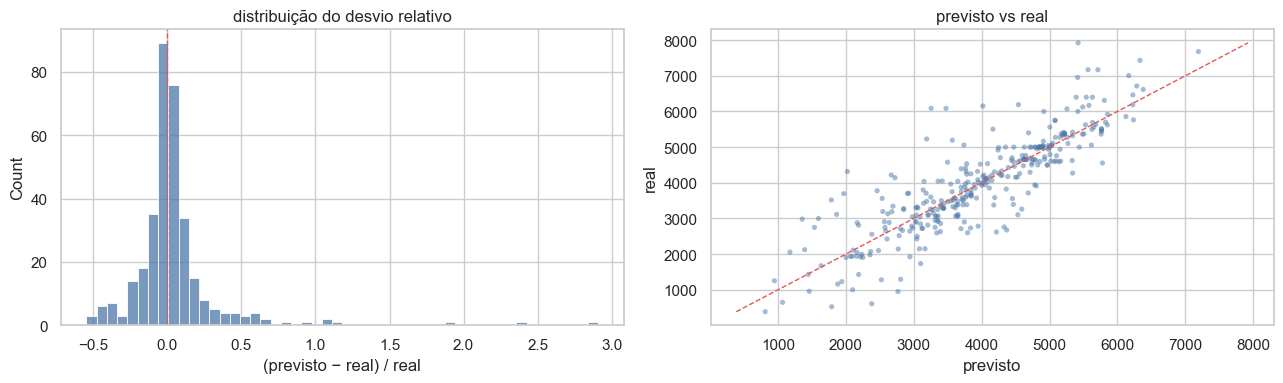

count    338.000
mean       0.044
std        0.318
min       -0.545
25%       -0.063
50%        0.004
75%        0.082
max        2.908


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(teste["erro_pct"], bins=50, color="#4C78A8", ax=axes[0])
axes[0].axvline(0, color="#E45756", ls="--", lw=1)
axes[0].set_title("distribuição do desvio relativo")
axes[0].set_xlabel("(previsto − real) / real")

axes[1].scatter(teste["previsto"], teste[ALVO], s=14, alpha=.5,
                color="#4C78A8", edgecolors="none")
lims = [teste[[ALVO, "previsto"]].min().min(), teste[[ALVO, "previsto"]].max().max()]
axes[1].plot(lims, lims, ls="--", color="#E45756", lw=1)
axes[1].set_xlabel("previsto"); axes[1].set_ylabel("real")
axes[1].set_title("previsto vs real")
plt.tight_layout(); plt.show()

print(teste["erro_pct"].describe().round(3).to_string())

## 6.2 A lista

In [12]:
COLS_RES = ["ad_id", "titulo", "bairro", "tipologia", "area_m2",
            "preco_eur", ALVO, "previsto", "erro_pct", "estado_conservacao"]

print("=== 15 mais SUBVALORIZADOS (pedem menos do que o esperado) ===")
display(teste.nlargest(15, "erro_pct")[COLS_RES].round(2))

print("=== 15 mais SOBREVALORIZADOS ===")
display(teste.nsmallest(15, "erro_pct")[COLS_RES].round(2))

=== 15 mais SUBVALORIZADOS (pedem menos do que o esperado) ===


,ad_id,titulo,bairro,tipologia,area_m2,preco_eur,preco_m2,previsto,erro_pct,estado_conservacao
1247,19116105,Casa / Villa T2 em Torres do Mondego de 64 m2,NaN,T2,64.0,39000.0,609.38,2381.68,2.91,to_renovation
1279,16932052,Casa para Reconstrução (Coimbra),Alta - Praça da República,T2,100.0,52500.0,525.00,1792.26,2.41,to_renovation
1296,17419927,Moradia com vistas deslumbrantes sobre Coimbra,Santa Clara,T4,368.0,350000.0,951.09,2767.57,1.91,to_renovation
1342,18592818,"Casa T4 em São Martinho do Bispo e Ribeira de Frades de 85,00 m2",São Martinho do Bispo,T4,85.0,110000.0,1294.12,2806.63,1.17,ready_to_use
1373,18924455,Moradia | Para recuperar | Habitação + Terreno | Oportunidade,São Martinho do Bispo,T6,200.0,77000.0,385.00,812.42,1.11,to_renovation
1238,19192204,"Moradia para Recuperar | Casal da Rosa, Eiras",São Paulo de Frades,T1,35.0,35000.0,1000.00,2099.37,1.10,to_renovation
1367,18956474,Moradia T5 | São Martinho do Bispo | c/ Garagem,São Martinho do Bispo,T5,168.0,215000.0,1279.76,2523.24,0.97,ready_to_use
987,19155960,T2 com Potencial em Santa Clara c/parqueamento exterior - Coi...,Santa Clara,T2,74.4,129000.0,1733.87,3101.84,0.79,ready_to_use
1248,19085114,Moradia T4 para venda,Eiras,T4,243.0,157500.0,648.15,1067.59,0.65,NaN
776,18874582,Apartamento T2,Alta - Praça da República,T2,65.0,174000.0,2676.92,4368.63,0.63,ready_to_use


=== 15 mais SOBREVALORIZADOS ===


,ad_id,titulo,bairro,tipologia,area_m2,preco_eur,preco_m2,previsto,erro_pct,estado_conservacao
1366,18932410,Moradia T10 para venda,São Martinho do Bispo,T9+,218.0,650000.0,2981.65,1357.67,-0.54,to_renovation
1221,18563697,Moradia Isolada M6 com aparcamento em Celas,Celas,T5,278.0,1200000.0,4316.55,2022.77,-0.53,ready_to_use
1353,19180177,Moradia T4 com Piscina Coberta em Coimbra,São Martinho do Bispo,T4,341.0,1200000.0,3519.06,1786.25,-0.49,ready_to_use
1369,18976936,"Moradia T4 com três frentes, Fânzeres junto à Avenida da Conduta",São Martinho do Bispo,T4,200.0,600000.0,3000.00,1596.15,-0.47,ready_to_use
794,17166168,"Apartamento T5 no coração da cidade de Coimbra, Baixa",Baixa,T5,230.0,850000.0,3695.65,1969.50,-0.47,ready_to_use
913,19212375,"Penthouse T5 | Les Terrasses – Quinta das Lágrimas, Coimbra",Santa Clara,T5,230.0,1400000.0,6086.96,3255.76,-0.47,to_completion
784,18740979,Apartamento T3 à venda em Santo António dos Olivais,Alta - Praça da República,T3,200.0,550000.0,2750.00,1537.71,-0.44,NaN
891,19213631,Apartamento T5 para venda,Santa Clara,T5,230.0,1400000.0,6086.96,3475.85,-0.43,NaN
1377,18765567,Moradia T2 para venda,São Martinho do Bispo,T2,90.0,185000.0,2055.56,1176.82,-0.43,NaN
1240,19164653,Moradia T3 para venda,Eiras,T3,122.0,380000.0,3114.75,1863.33,-0.40,NaN


*Lê os títulos, como fizeste na limpeza. As perguntas:*

- *Os subvalorizados têm alguma coisa em comum que o modelo não vê?*
- *Aparecem casas para recuperar? Se sim, o `precisa_obras` não está a chegar.*
- *Algum é contaminação que escapou às regras do `02`?*

*Abre três ou quatro `url` e confirma. É esta verificação que separa uma lista
de números de um resultado defensável.*

## 6.3 ajuste ao viés

In [13]:
# O modelo sobrestima os baratos e subestima os caros. Sem corrigir, os maiores
# desvios positivos seriam simplesmente os imóveis mais baratos.
teste["faixa"] = pd.qcut(teste[ALVO], 4, labels=["Q1", "Q2", "Q3", "Q4"])
vies_faixa = teste.groupby("faixa", observed=True)["erro_pct"].transform("median")
teste["desvio_ajustado"] = teste["erro_pct"] - vies_faixa

print("viés mediano por faixa (subtraído a cada anúncio):")
print(teste.groupby("faixa", observed=True)["erro_pct"].median().round(3).to_string())

# Casas para recuperar são um mercado à parte: valem 61% menos por m², com
# desconto a variar entre 40% e 85%. Comparar uma ruína com o padrão geral não
# faz sentido — compara-se com outras ruínas.
normais = teste[~teste.precisa_obras]
obras = teste[teste.precisa_obras].copy()
obras["desvio_entre_pares"] = obras["erro_pct"] - obras["erro_pct"].median()

print(f"\nprontos a habitar: {len(normais)} | para recuperar: {len(obras)}")

brutos = set(teste.nlargest(15, "erro_pct").ad_id)
ajustados = set(normais.nlargest(15, "desvio_ajustado").ad_id)
print(f"dos 15 candidatos brutos, sobrevivem ao ajuste: {len(brutos & ajustados)}")

viés mediano por faixa (subtraído a cada anúncio):
faixa
Q1    0.140
Q2    0.011
Q3   -0.011
Q4   -0.032

prontos a habitar: 301 | para recuperar: 37
dos 15 candidatos brutos, sobrevivem ao ajuste: 6


In [14]:
COLS_AJ = COLS_RES + ["desvio_ajustado", "faixa"]

print("=== candidatos entre imóveis PRONTOS A HABITAR ===")
display(normais.nlargest(10, "desvio_ajustado")[COLS_AJ].round(2))

print("=== casas PARA RECUPERAR, comparadas entre si ===")
display(obras.nlargest(8, "desvio_entre_pares")[
    COLS_RES + ["desvio_entre_pares"]].round(2))

=== candidatos entre imóveis PRONTOS A HABITAR ===


,ad_id,titulo,bairro,tipologia,area_m2,preco_eur,preco_m2,previsto,erro_pct,estado_conservacao,desvio_ajustado,faixa
1367,18956474,Moradia T5 | São Martinho do Bispo | c/ Garagem,São Martinho do Bispo,T5,168.00,215000.0,1279.76,2523.24,0.97,ready_to_use,0.83,Q1
1248,19085114,Moradia T4 para venda,Eiras,T4,243.00,157500.0,648.15,1067.59,0.65,NaN,0.51,Q1
776,18874582,Apartamento T2,Alta - Praça da República,T2,65.00,174000.0,2676.92,4368.63,0.63,ready_to_use,0.49,Q1
1206,19044543,Moradia T8 (T0+T3+T4) no Norton de Matos- Alta Rentabilidade,Bairro Norton de Matos,T8,187.00,489900.0,2619.79,4216.69,0.61,ready_to_use,0.47,Q1
442,19033270,Apartamento T1 para venda,Alto de S. João - Portela - Pinhal de Marrocos,T1,86.95,269841.0,3103.40,4533.73,0.46,ready_to_use,0.45,Q2
1341,19228171,"Moradias Geminadas Alqueves São Martinho do Bispo, Coimbra",São Martinho do Bispo,T9,232.00,285000.0,1228.45,1940.81,0.58,NaN,0.44,Q1
1216,18827735,Apartamento T3 no Tovim - Coimbra,Tovim - Casal do Lobo - Vale de Canas,T3,67.00,185000.0,2761.19,4332.45,0.57,ready_to_use,0.43,Q1
152,19197702,"Apartamento T1+1 na Avenida Fernão Magalhães, Coimbra",Olivais,T1,61.00,199000.0,3262.30,4590.70,0.41,ready_to_use,0.40,Q2
1325,18863999,"Moradia T3 com piscina, logradouro e terreno - Assafarge",Castelo Viegas,T4,200.00,385000.0,1925.00,2943.68,0.53,ready_to_use,0.39,Q1
6,19032113,T4 na Avenida Elísio de Moura,Solum,T4,165.00,429000.0,2600.00,3793.22,0.46,ready_to_use,0.32,Q1


=== casas PARA RECUPERAR, comparadas entre si ===


,ad_id,titulo,bairro,tipologia,area_m2,preco_eur,preco_m2,previsto,erro_pct,estado_conservacao,desvio_entre_pares
1247,19116105,Casa / Villa T2 em Torres do Mondego de 64 m2,NaN,T2,64.0,39000.0,609.38,2381.68,2.91,to_renovation,2.81
1279,16932052,Casa para Reconstrução (Coimbra),Alta - Praça da República,T2,100.0,52500.0,525.00,1792.26,2.41,to_renovation,2.32
1296,17419927,Moradia com vistas deslumbrantes sobre Coimbra,Santa Clara,T4,368.0,350000.0,951.09,2767.57,1.91,to_renovation,1.82
1342,18592818,"Casa T4 em São Martinho do Bispo e Ribeira de Frades de 85,00 m2",São Martinho do Bispo,T4,85.0,110000.0,1294.12,2806.63,1.17,ready_to_use,1.07
1373,18924455,Moradia | Para recuperar | Habitação + Terreno | Oportunidade,São Martinho do Bispo,T6,200.0,77000.0,385.00,812.42,1.11,to_renovation,1.02
1238,19192204,"Moradia para Recuperar | Casal da Rosa, Eiras",São Paulo de Frades,T1,35.0,35000.0,1000.00,2099.37,1.10,to_renovation,1.00
987,19155960,T2 com Potencial em Santa Clara c/parqueamento exterior - Coi...,Santa Clara,T2,74.4,129000.0,1733.87,3101.84,0.79,ready_to_use,0.69
1289,19109200,Moradia com projecto de arquitectura em Santa Clara,Santa Clara,T2,99.0,115000.0,1161.62,1880.70,0.62,NaN,0.52


## 6.4 Verificação

In [15]:
for _, r in normais.nlargest(5, "desvio_ajustado").iterrows():
    print(f"{r.ad_id} | {r.preco_m2:.0f} €/m² pedidos, {r.previsto:.0f} previstos "
          f"({r.desvio_ajustado:+.0%})")
    print(f"   {r.titulo}")
    print(f"   {r.bairro} | {r.tipologia} | {r.area_m2:.0f} m² | {r.estado_conservacao}")
    print(f"   https://www.imovirtual.com/pt/anuncio/{r.slug}"
          if "slug" in r else "")
    print()

18956474 | 1280 €/m² pedidos, 2523 previstos (+83%)
   Moradia T5 | São Martinho do Bispo | c/ Garagem
   São Martinho do Bispo | T5 | 168 m² | ready_to_use


19085114 | 648 €/m² pedidos, 1068 previstos (+51%)
   Moradia T4 para venda
   Eiras | T4 | 243 m² | nan


18874582 | 2677 €/m² pedidos, 4369 previstos (+49%)
   Apartamento T2
   Alta - Praça da República | T2 | 65 m² | ready_to_use


19044543 | 2620 €/m² pedidos, 4217 previstos (+47%)
   Moradia T8 (T0+T3+T4) no Norton de Matos- Alta Rentabilidade
   Bairro Norton de Matos | T8 | 187 m² | ready_to_use


19033270 | 3103 €/m² pedidos, 4534 previstos (+45%)
   Apartamento T1 para venda
   Alto de S. João - Portela - Pinhal de Marrocos | T1 | 87 m² | ready_to_use




---
## 7. O que o modelo aprendeu

Importância por permutação: mede quanto o desempenho piora ao baralhar cada
coluna. Ao contrário da importância interna das árvores, não é enviesada a
favor de variáveis com muitos valores distintos.

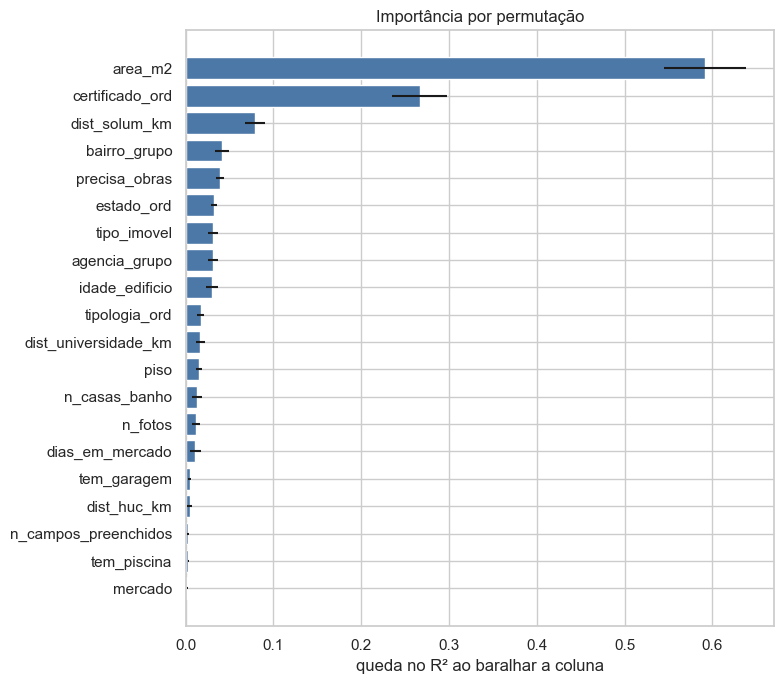

,feature,importancia,desvio
0,area_m2,0.5916,0.0465
3,certificado_ord,0.2665,0.0310
9,dist_solum_km,0.0788,0.0112
14,bairro_grupo,0.0411,0.0080
33,precisa_obras,0.0392,0.0045
4,estado_ord,0.0327,0.0034
15,tipo_imovel,0.0311,0.0056
16,agencia_grupo,0.0311,0.0059
2,idade_edificio,0.0300,0.0065
1,tipologia_ord,0.0172,0.0038


In [16]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelo, X_teste, y_teste, n_repeats=10,
                             random_state=42, scoring="r2")
ordem = pd.DataFrame({"feature": FEATURES,
                      "importancia": imp.importances_mean,
                      "desvio": imp.importances_std}).sort_values(
                          "importancia", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
top = ordem.head(20)
ax.barh(top.feature, top.importancia, xerr=top.desvio, color="#4C78A8")
ax.invert_yaxis(); ax.set_xlabel("queda no R² ao baralhar a coluna")
ax.set_title("Importância por permutação")
plt.tight_layout(); plt.show()

display(ordem.head(20).round(4))

*Bate certo com o que o `01` mostrou? A idade do edifício e o bairro deviam
estar no topo. Se aparecer algo inesperado em primeiro lugar, é sinal para
investigar antes de aceitar.*

---
## 8. Aplicar aos anúncios sem preço

Os 13 que o anunciante escondeu. Não serviram para treinar, mas são o caso de
uso mais directo do modelo.

In [17]:
if len(sem_alvo):
    sem_alvo["preco_m2_estimado"] = modelo.predict(sem_alvo[FEATURES])
    sem_alvo["preco_estimado_eur"] = (sem_alvo["preco_m2_estimado"]
                                      * sem_alvo["area_m2"]).round(-2)
    display(sem_alvo[["ad_id", "titulo", "bairro", "tipologia", "area_m2",
                      "preco_m2_estimado", "preco_estimado_eur"]].round(0))

,ad_id,titulo,bairro,tipologia,area_m2,preco_m2_estimado,preco_estimado_eur
40,19129130,Apartamento T2 com Sótão na Solum,Quinta da Maia,T2,74.0,3313.0,245200.0
165,19188402,Grande T5 Duplex + terraço + garagem,Alto de S. João - Portela - Pinhal de Marrocos,T5,250.0,2288.0,571900.0
187,19182855,Apartamento T2 Rua de Macau Bairro Norton de Matos - Remodelado,Bairro Norton de Matos,T2,60.0,4151.0,249100.0
262,19151745,T4 em último piso no condomínio fechado ZEN,Alto de S. João - Portela - Pinhal de Marrocos,T0,185.0,5227.0,966900.0
367,19088388,T4 em último piso no condomínio fechado ZEN,Alto de S. João - Portela - Pinhal de Marrocos,T4,185.0,5381.0,995500.0
492,18903356,Apartamento T4 | Condomínio Zen | Quinta da Portela,Alto de S. João - Portela - Pinhal de Marrocos,T4,200.0,4589.0,917900.0
493,18903294,Apartamento T4 | Condomínio Zen | Quinta da Portela,Alto de S. João - Portela - Pinhal de Marrocos,T4,200.0,4434.0,886900.0
526,18663761,Apartamento T4 para venda,Alto de S. João - Portela - Pinhal de Marrocos,T4,174.0,4179.0,727200.0
551,18042508,Apartamento T3 com varanda e garagem para 2 carros,Casa Branca,T3,125.0,4416.0,552000.0
835,19234696,Voluta,Santa Clara,T2,503.0,3353.0,1685200.0


---
## 9. Guardar

In [18]:
import joblib

(OUTPUTS / "modelos").mkdir(parents=True, exist_ok=True)
(OUTPUTS / "figuras").mkdir(parents=True, exist_ok=True)

# joblib.dump(modelo, OUTPUTS / "modelos" / "preco_m2.joblib")
# teste.to_csv(OUTPUTS / "residuos_teste.csv", index=False, encoding="utf-8")
# print("modelo e resíduos guardados")

---
## Conclusão

*Preencher no fim.*

| | |
|---|---|
| MAE | ? €/m² |
| erro mediano | ? % |
| R² | ? |
| melhor que a mediana em | ? |

**O que explica o preço:**

**Onde o modelo falha:**

**Os candidatos a subvalorizados, verificados à mão:**

**Limitações:**

- preço **pedido**, não de venda — o modelo aprende o que os vendedores pedem
- não vê o interior, a vista, o ruído nem a exposição solar
- ~1 380 anúncios, uma recolha única em Agosto de 2026